# RA3 — Parte 2: Visualizações e interpretação

Este notebook reúne os gráficos das perguntas P1 a P6, originalmente produzidos no notebook do RA1 (`HorrorMovieAnalysis.ipynb`), agora com título, nome dos eixos, unidades e legenda conferidos. Cada gráfico vem acompanhado de uma interpretação curta.

Os cálculos são os mesmos do RA1, feitos sobre a base limpa `horror_movies_limpo.csv`.

## Preparação do ambiente

In [80]:
# Bibliotecas para manipulação e visualização dos dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações que deixam os resultados mais legíveis durante a aula
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("✓ Ambiente preparado.")

✓ Ambiente preparado.


## Carregamento da base limpa

A base é lida informando os tipos de cada coluna, do mesmo jeito que no fim do RA1, para que os valores ausentes continuem vazios e não virem zero. O arquivo local tem prioridade; se ele não existir (por exemplo, no Colab), a base é baixada do GitHub em uma versão fixa.

In [81]:
from pathlib import Path

tipos_csv = {
    "collection": "Int64", "budget": "Int64", "revenue": "Int64", "runtime": "Int64",
    "idioma": "string", "formato": "string", "nota_confiavel": "boolean",
    "ingles": "boolean", "franquia": "boolean",
}
arquivo_local = Path("horror_movies_limpo.csv")
url_csv = (
    "https://raw.githubusercontent.com/carlaferraz/HorrorMoviesData/"
    "e0bfb2b41182d7612323195c60c21818ce5df6a3/"
    "horror_movies_limpo.csv"
)
fonte_csv = arquivo_local if arquivo_local.exists() else url_csv

df = pd.read_csv(
    fonte_csv,
    parse_dates=["release_date"],
    dtype=tipos_csv,
)

print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")

Linhas: 32,404 | Colunas: 25


## Regras usadas em todos os gráficos

- **Nota:** só entram filmes com `nota_confiavel` (10 votos ou mais).
- **Orçamento, receita e retorno:** só entram filmes com o valor informado.
- **Mediana em vez de média** quando a distribuição é muito assimétrica (popularidade, receita e retorno).

In [82]:
COR_PRINCIPAL = "#ff9aeb"
COR_DESTAQUE = "#eb34ae"
COR_NEUTRA = "#b5b3ad"

com_nota = df[df["nota_confiavel"]]
print(f"Filmes na base limpa: {len(df):,}")
print(f"Com nota confiável: {len(com_nota):,}")
print(f"Com orçamento informado: {int(df['budget'].notna().sum()):,}")
print(f"Com retorno calculado (orçamento e receita): {int(df['retorno'].notna().sum()):,}")

Filmes na base limpa: 32,404
Com nota confiável: 8,477
Com orçamento informado: 4,215
Com retorno calculado (orçamento e receita): 1,010


## P1 — Lançamentos por década e participação de outros idiomas

Pergunta: como o número de lançamentos de terror variou por década entre 1950 e 2022, e como mudou a participação de filmes em idiomas diferentes do inglês?

,filmes,nao_ingles,% não inglês
década,,,
1950s,340,136,40.0%
1960s,769,385,50.1%
1970s,"1,626",734,45.1%
1980s,"2,563","1,103",43.0%
1990s,"2,558",991,38.7%
2000s,"5,670","1,728",30.5%
2010s,"13,387","3,973",29.7%
2020s,"5,491","1,521",27.7%


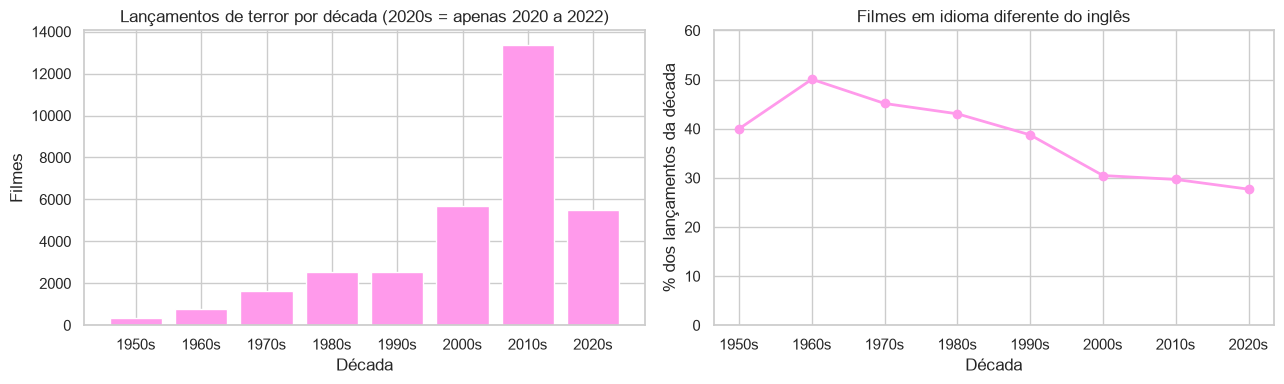

In [83]:
por_decada = df.groupby("decada").agg(
    filmes=("id", "size"),
    nao_ingles=("ingles", lambda serie: int((~serie).sum())),
)
por_decada["% não inglês"] = por_decada["nao_ingles"] / por_decada["filmes"] * 100
por_decada.index = [f"{decada}s" for decada in por_decada.index]
por_decada.index.name = "década"
display(por_decada.style.format({"filmes": "{:,}", "nao_ingles": "{:,}", "% não inglês": "{:.1f}%"}))

fig, (eixo_filmes, eixo_idioma) = plt.subplots(1, 2, figsize=(13, 4))
eixo_filmes.bar(por_decada.index, por_decada["filmes"], color=COR_PRINCIPAL)
eixo_filmes.set_title("Lançamentos de terror por década (2020s = apenas 2020 a 2022)")
eixo_filmes.set_ylabel("Filmes")
eixo_filmes.set_xlabel("Década")

eixo_idioma.plot(por_decada.index, por_decada["% não inglês"], color=COR_PRINCIPAL, linewidth=2, marker="o")
eixo_idioma.set_title("Filmes em idioma diferente do inglês")
eixo_idioma.set_xlabel("Década")
eixo_idioma.set_ylabel("% dos lançamentos da década")
eixo_idioma.set_ylim(0, 60)
plt.tight_layout()
plt.show()

**Interpretação:** o número de lançamentos cresceu fortemente a partir dos anos 2000: só a década de 2010 tem 13.387 filmes (41% da base), e 2020–2022 já se aproxima da década de 2000 inteira. A participação de filmes em idioma diferente do inglês caiu de 50,1% nos anos 1960 para 27,7% em 2020–2022.

## P2 — Orçamento e avaliação

Pergunta: filmes de terror com maior orçamento recebem avaliações médias maiores do público?

O orçamento é dividido em quatro faixas com a mesma quantidade aproximada de filmes (quartis).

Filmes analisados: 2,122
Correlação de Spearman entre orçamento e nota: 0.31


,filmes,orcamento_min,orcamento_max,nota_media,nota_mediana
faixa de orçamento,,,,,
1 - mais baixo,584,"US$ 1,000","US$ 500,000",5.07,5.0
2,480,"US$ 520,000","US$ 2,300,000",5.29,5.3
3,528,"US$ 2,393,600","US$ 8,000,000",5.60,5.7
4 - mais alto,530,"US$ 8,300,000","US$ 200,000,000",5.96,6.0


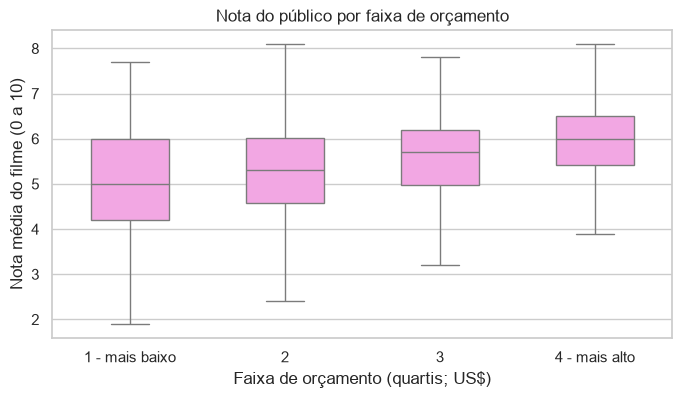

In [84]:
base_p2 = com_nota[com_nota["budget"].notna()].copy()
orcamento = base_p2["budget"].astype(float)
correlacao = orcamento.rank().corr(base_p2["vote_average"].rank())

FAIXAS = ["1 - mais baixo", "2", "3", "4 - mais alto"]
base_p2["faixa de orçamento"] = pd.qcut(orcamento, 4, labels=FAIXAS)
p2 = base_p2.groupby("faixa de orçamento", observed=True).agg(
    filmes=("id", "size"),
    orcamento_min=("budget", "min"),
    orcamento_max=("budget", "max"),
    nota_media=("vote_average", "mean"),
    nota_mediana=("vote_average", "median"),
)

print(f"Filmes analisados: {len(base_p2):,}")
print(f"Correlação de Spearman entre orçamento e nota: {correlacao:.2f}")
display(p2.style.format({
    "orcamento_min": "US$ {:,.0f}", "orcamento_max": "US$ {:,.0f}",
    "nota_media": "{:.2f}", "nota_mediana": "{:.1f}",
}))

plt.figure(figsize=(8, 4))
sns.boxplot(data=base_p2, x="faixa de orçamento", y="vote_average", color=COR_PRINCIPAL,
            showfliers=False, width=0.5)
plt.title("Nota do público por faixa de orçamento")
plt.xlabel("Faixa de orçamento (quartis; US$)")
plt.ylabel("Nota média do filme (0 a 10)")
plt.show()

**Interpretação:** a nota média sobe a cada faixa, de 5,07 nos filmes mais baratos (até US$ 500 mil) para 5,96 nos mais caros (a partir de US$ 8,3 milhões), mas a correlação de Spearman é fraca (0,31) e as caixas se sobrepõem bastante. A comparação cobre 2.122 filmes com orçamento e nota confiável, cerca de 7% da base.

## P3 — Retorno proporcional por faixa de orçamento

Pergunta: entre os filmes com orçamento e receita informados, os de baixo orçamento apresentam retorno proporcional (receita ÷ orçamento) maior que os de alto orçamento?

Retorno 2 significa que o filme faturou o dobro do que custou.

Filmes analisados: 1,010


,filmes,orcamento_min,orcamento_max,retorno_mediano,retorno_medio,pct_receita_maior
faixa de orçamento,,,,,,
1 - mais baixo,253,"US$ 1,000","US$ 1,800,000",3.08×,78.86×,70.8%
2,253,"US$ 1,900,000","US$ 6,500,000",2.00×,5.08×,63.2%
3,266,"US$ 6,600,000","US$ 17,000,000",2.13×,4.08×,68.4%
4 - mais alto,238,"US$ 18,000,000","US$ 200,000,000",2.03×,2.45×,73.5%


Maiores retornos da base:


title,ano,budget,revenue,retorno
One Cut of the Dead,2017,"US$ 30,000","US$ 200,000,000","6,667×"
The Blair Witch Project,1999,"US$ 60,000","US$ 248,639,099","4,144×"
Routs,2022,"US$ 25,000","US$ 50,000,000","2,000×"
Paranormal Activity,2007,"US$ 215,000","US$ 194,183,034",903×
Lady Frankenstein,1971,"US$ 200,000","US$ 139,683,000",698×


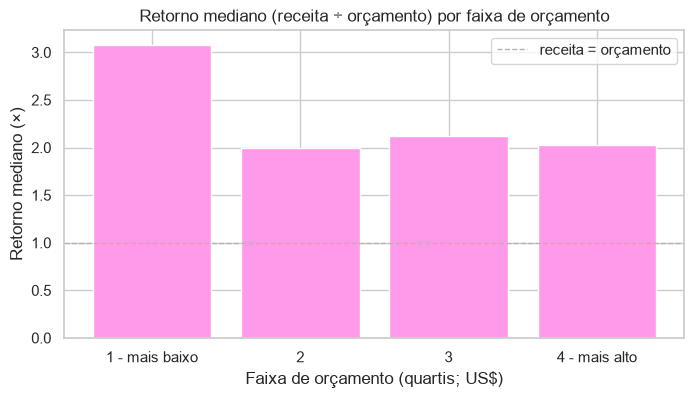

In [85]:
base_p3 = df[df["retorno"].notna()].copy()
base_p3["faixa de orçamento"] = pd.qcut(base_p3["budget"].astype(float), 4, labels=FAIXAS)
p3 = base_p3.groupby("faixa de orçamento", observed=True).agg(
    filmes=("id", "size"),
    orcamento_min=("budget", "min"),
    orcamento_max=("budget", "max"),
    retorno_mediano=("retorno", "median"),
    retorno_medio=("retorno", "mean"),
    pct_receita_maior=("retorno", lambda serie: (serie > 1).mean() * 100),
)

print(f"Filmes analisados: {len(base_p3):,}")
display(p3.style.format({
    "orcamento_min": "US$ {:,.0f}", "orcamento_max": "US$ {:,.0f}",
    "retorno_mediano": "{:.2f}×", "retorno_medio": "{:.2f}×", "pct_receita_maior": "{:.1f}%",
}))

print("Maiores retornos da base:")
display(
    base_p3.nlargest(5, "retorno")[["title", "ano", "budget", "revenue", "retorno"]]
    .style.hide(axis="index")
    .format({"budget": "US$ {:,.0f}", "revenue": "US$ {:,.0f}", "retorno": "{:,.0f}×"})
)

plt.figure(figsize=(8, 4))
plt.bar(p3.index.astype(str), p3["retorno_mediano"], color=COR_PRINCIPAL)
plt.axhline(1, color=COR_NEUTRA, linestyle="--", linewidth=1, label="receita = orçamento")
plt.legend(loc="upper right")
plt.title("Retorno mediano (receita ÷ orçamento) por faixa de orçamento")
plt.xlabel("Faixa de orçamento (quartis; US$)")
plt.ylabel("Retorno mediano (×)")
plt.show()

**Interpretação:** o retorno mediano da faixa mais barata (até US$ 1,8 milhão) é 3,1×, contra cerca de 2× nas outras três faixas. Já a proporção de filmes que faturam mais do que custaram é parecida entre as faixas (de 63% a 74%). A análise cobre os 1.010 filmes com orçamento e receita informados.

## P4 — Gêneros combinados ao terror

Pergunta: quais gêneros aparecem com mais frequência combinados ao terror, e quais combinações têm melhor avaliação e popularidade?

Cada filme é desmembrado em uma linha por gênero, e o próprio "Horror" é retirado. Entram os gêneros presentes em pelo menos 300 filmes.

Filmes classificados só como Horror: 12,422 (38.3%)


,filmes,% dos filmes,filmes_com_nota,nota_media,popularidade_mediana
genero,,,,,
Thriller,"7,640",23.6%,"3,293",5.42,1.63
Comedy,"4,940",15.2%,"1,190",5.49,0.88
Drama,"4,254",13.1%,"1,296",5.74,0.91
Mystery,"3,125",9.6%,"1,285",5.72,1.40
Science Fiction,"2,703",8.3%,"1,333",5.14,1.96
Fantasy,"2,188",6.8%,738,5.70,1.11
Action,"1,959",6.0%,826,5.22,1.65
Crime,"1,151",3.6%,426,5.65,1.40
Animation,972,3.0%,174,6.47,0.60


Combinações exatas mais comuns:


,filmes
genre_names,
Horror,12422
"Horror, Thriller",3241
"Comedy, Horror",2831
"Drama, Horror",1323
"Horror, Science Fiction",923
"Horror, Mystery, Thriller",859


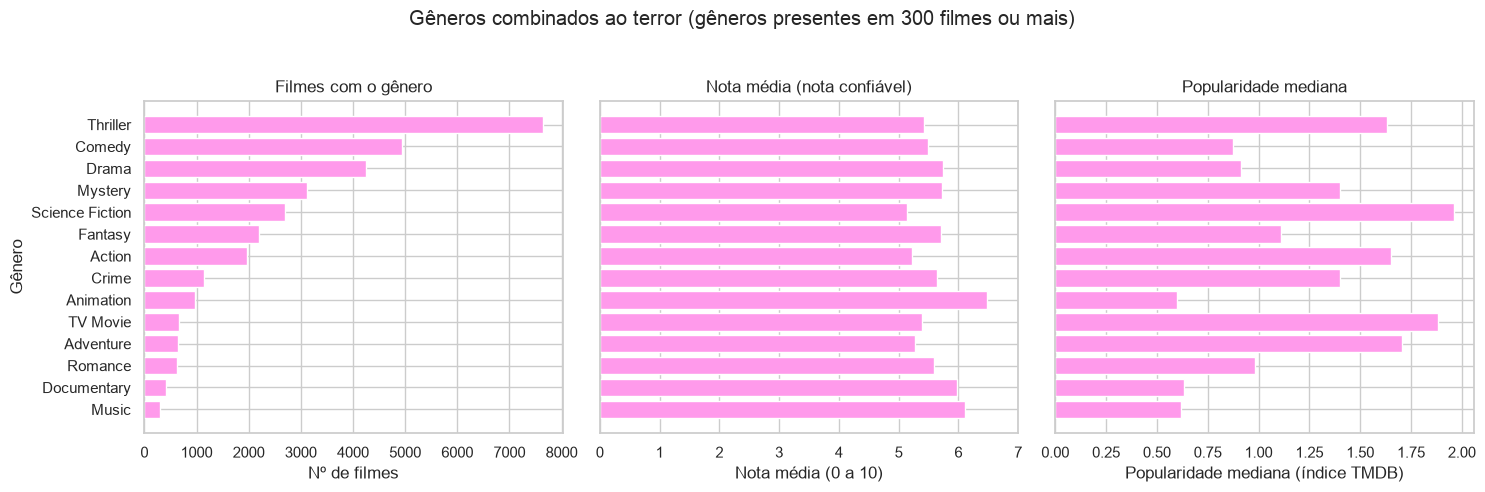

In [86]:
generos = (
    df.assign(genero=df["genre_names"].str.split(", "))
    .explode("genero")
    .query("genero != 'Horror'")
)
so_terror = int(df["genre_names"].eq("Horror").sum())
print(f"Filmes classificados só como Horror: {so_terror:,} ({so_terror / len(df):.1%})")

p4 = generos.groupby("genero").agg(
    filmes=("id", "size"),
    popularidade_mediana=("popularity", "median"),
).join(
    generos[generos["nota_confiavel"]].groupby("genero").agg(
        filmes_com_nota=("id", "size"),
        nota_media=("vote_average", "mean"),
    )
)
p4["% dos filmes"] = p4["filmes"] / len(df) * 100
p4 = p4[p4["filmes"].ge(300)].sort_values("filmes", ascending=False)

display(p4[["filmes", "% dos filmes", "filmes_com_nota", "nota_media", "popularidade_mediana"]].style.format({
    "filmes": "{:,}", "% dos filmes": "{:.1f}%", "filmes_com_nota": "{:,}",
    "nota_media": "{:.2f}", "popularidade_mediana": "{:.2f}",
}))

print("Combinações exatas mais comuns:")
display(df["genre_names"].value_counts().head(6).rename("filmes").to_frame())

fig, eixos = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
ordem = p4.index[::-1]
for eixo, coluna, titulo in zip(
    eixos,
    ["filmes", "nota_media", "popularidade_mediana"],
    ["Filmes com o gênero", "Nota média (nota confiável)", "Popularidade mediana"],
):
    eixo.barh(ordem, p4.loc[ordem, coluna], color=COR_PRINCIPAL)
    eixo.set_title(titulo)
eixos[0].set_xlabel("Nº de filmes")
eixos[1].set_xlabel("Nota média (0 a 10)")
eixos[2].set_xlabel("Popularidade mediana (índice TMDB)")
eixos[0].set_ylabel("Gênero")
eixos[1].set_xlim(0, 7)
fig.suptitle("Gêneros combinados ao terror (gêneros presentes em 300 filmes ou mais)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Interpretação:** os nomes dos gêneros estão em inglês, como na base. **Thriller** é o parceiro mais frequente (7.640 filmes, 23,6% da base), seguido de Comedy, Drama e Mystery, enquanto 38,3% dos filmes são classificados só como Horror. As maiores notas médias são de Animation (6,47), Music (6,12) e Documentary (5,97); as maiores popularidades medianas são de Science Fiction (1,96), TV Movie (1,88), Adventure e Action, que têm notas entre 5,14 e 5,39.

## P5 — Lançamentos em outubro

Pergunta: existe concentração de lançamentos em outubro (período do Halloween), e os filmes lançados nesse mês têm popularidade diferente dos demais?

As datas de **1º de janeiro** ficam fora desta contagem: o TMDB grava essa data quando só o ano do lançamento é conhecido, o que inflaria janeiro.

Filmes com data em 1º de janeiro: 3,836 de 5,582 lançados em janeiro
Lançados exatamente em 31 de outubro: 503


,filmes,popularidade_mediana,popularidade_media,nota_media,filmes por mês
periodo,,,,,
outros meses,"23,798",0.88,4.50,5.37,"2,163"
outubro,"4,770",0.84,3.83,5.39,"4,770"


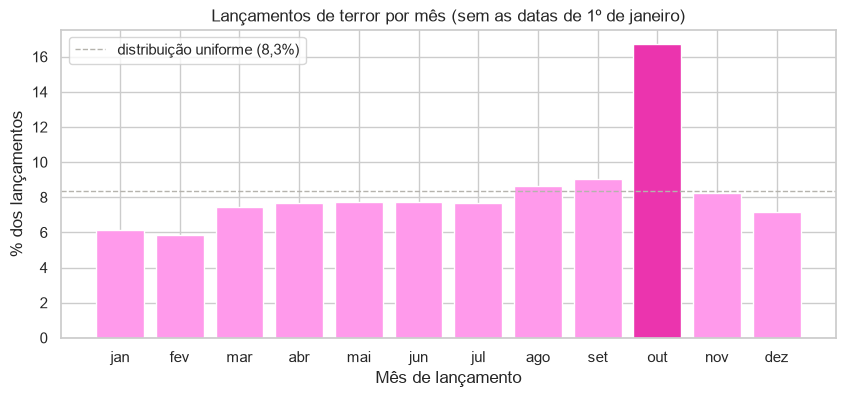

In [87]:
primeiro_janeiro = df["release_date"].dt.month.eq(1) & df["release_date"].dt.day.eq(1)
print(f"Filmes com data em 1º de janeiro: {int(primeiro_janeiro.sum()):,} "
      f"de {int(df['mes'].eq(1).sum()):,} lançados em janeiro")

base_p5 = df[~primeiro_janeiro].copy()
base_p5["periodo"] = np.where(base_p5["mes"].eq(10), "outubro", "outros meses")

nomes_meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
por_mes = base_p5["mes"].value_counts(normalize=True).sort_index().mul(100)
por_mes.index = nomes_meses

outubro_31 = int((base_p5["mes"].eq(10) & base_p5["release_date"].dt.day.eq(31)).sum())
print(f"Lançados exatamente em 31 de outubro: {outubro_31:,}")

p5 = base_p5.groupby("periodo").agg(
    filmes=("id", "size"),
    popularidade_mediana=("popularity", "median"),
    popularidade_media=("popularity", "mean"),
).join(base_p5[base_p5["nota_confiavel"]].groupby("periodo").agg(nota_media=("vote_average", "mean")))
p5["filmes por mês"] = p5["filmes"] / np.where(p5.index == "outubro", 1, 11)
display(p5.style.format({
    "filmes": "{:,}", "filmes por mês": "{:,.0f}", "popularidade_mediana": "{:.2f}",
    "popularidade_media": "{:.2f}", "nota_media": "{:.2f}",
}))

plt.figure(figsize=(10, 4))
plt.bar(por_mes.index, por_mes.values,
        color=[COR_DESTAQUE if mes == "out" else COR_PRINCIPAL for mes in por_mes.index])
plt.axhline(100 / 12, color=COR_NEUTRA, linestyle="--", linewidth=1, label="distribuição uniforme (8,3%)")
plt.legend(loc="upper left")
plt.title("Lançamentos de terror por mês (sem as datas de 1º de janeiro)")
plt.xlabel("Mês de lançamento")
plt.ylabel("% dos lançamentos")
plt.show()

**Interpretação:** sem as 3.836 datas de 1º de janeiro, outubro concentra 16,7% dos lançamentos, o dobro da distribuição uniforme (8,3%) e quase o dobro do segundo colocado, setembro (9,0%). A popularidade mediana de outubro (0,84) é próxima à dos outros meses (0,88), assim como a nota média (5,39 contra 5,37).

## P6 — Filmes de franquia e filmes avulsos

Pergunta: filmes que pertencem a uma franquia têm avaliação e receita diferentes de filmes avulsos?

,filmes,filmes com nota,nota média,filmes com receita,receita mediana,retorno mediano,popularidade mediana
franquia,"2,302","1,447",5.50,467,"US$ 22,000,000",3.52×,3.80
avulso,"30,102","7,030",5.32,"1,016","US$ 2,064,798",1.22×,0.71


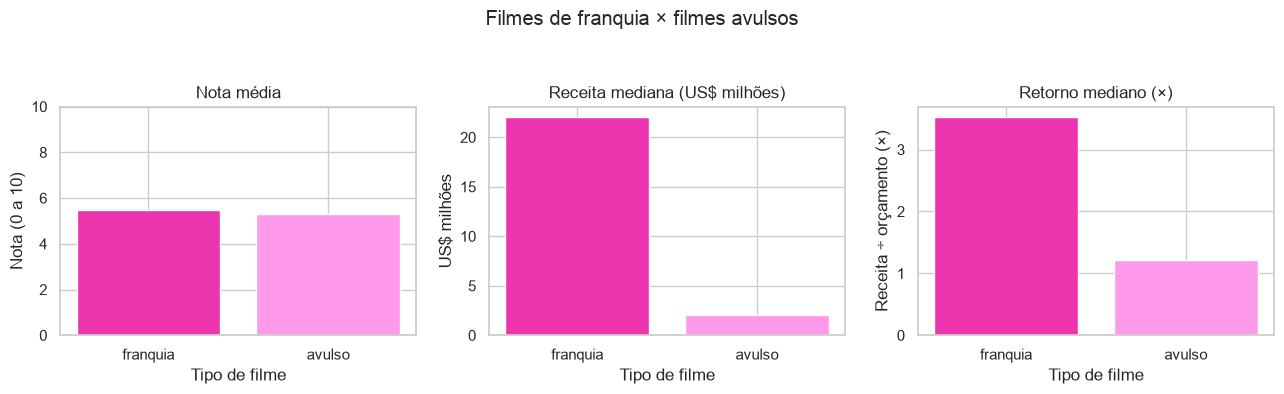

In [88]:
grupos = {True: "franquia", False: "avulso"}
p6 = pd.DataFrame({
    "filmes": df.groupby("franquia")["id"].size(),
    "filmes com nota": com_nota.groupby("franquia")["id"].size(),
    "nota média": com_nota.groupby("franquia")["vote_average"].mean(),
    "filmes com receita": df[df["revenue"].notna()].groupby("franquia")["id"].size(),
    "receita mediana": df.groupby("franquia")["revenue"].median(),
    "retorno mediano": df.groupby("franquia")["retorno"].median(),
    "popularidade mediana": df.groupby("franquia")["popularity"].median(),
}).rename(index=grupos).loc[["franquia", "avulso"]].rename_axis(None)

display(p6.style.format({
    "filmes": "{:,}", "filmes com nota": "{:,}", "nota média": "{:.2f}", "filmes com receita": "{:,}",
    "receita mediana": "US$ {:,.0f}", "retorno mediano": "{:.2f}×", "popularidade mediana": "{:.2f}",
}))

fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
cores = [COR_DESTAQUE, COR_PRINCIPAL]
for eixo, coluna, titulo, escala in zip(
    eixos,
    ["nota média", "receita mediana", "retorno mediano"],
    ["Nota média", "Receita mediana (US$ milhões)", "Retorno mediano (×)"],
    [1, 1e6, 1],
):
    eixo.bar(p6.index, p6[coluna] / escala, color=cores)
    eixo.set_title(titulo)
    eixo.set_xlabel("Tipo de filme")
eixos[0].set_ylabel("Nota (0 a 10)")
eixos[1].set_ylabel("US$ milhões")
eixos[2].set_ylabel("Receita ÷ orçamento (×)")
eixos[0].set_ylim(0, 10)
fig.suptitle("Filmes de franquia × filmes avulsos")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Interpretação:** a nota média é próxima (5,50 para filmes de franquia contra 5,32 para avulsos), mas a receita mediana da franquia é cerca de dez vezes maior (US$ 22 milhões contra US$ 2,1 milhões) e o retorno mediano é 3,5× contra 1,2×. A popularidade mediana também é bem maior (3,80 contra 0,71).

# RA3 — Parte 3: Machine Learning

Esta parte treina um modelo de machine learning sobre a mesma base limpa do RA1, para responder a uma pergunta de classificação: **um filme de terror vai ser bem avaliado pelo público?**

**Alvo:** `bem_avaliado`, 1 quando `vote_average` ≥ 6 e 0 caso contrário, calculado só para os filmes com nota confiável (10 votos ou mais, mesma regra do RA1 e do RA3 Parte 1).

**Abordagem:** K-Nearest Neighbors (KNN), um classificador que prevê a classe de um filme pela maioria (ou proporção) das classes dos filmes mais parecidos com ele no conjunto de treino. O `k` (quantidade de vizinhos) e o limiar de decisão são escolhidos por validação cruzada, e o resultado é comparado a chutes simples (um modelo "aprende algo" só se superar esses chutes).

**Instruções de execução e verificação:** execute as células desta seção em ordem, depois das da Parte 2 (elas reaproveitam a base `df` já carregada). Pontos para conferir:
- a célula de carregamento deve imprimir `Linhas: 32,404 | Colunas: 25`;
- a célula do alvo deve imprimir `Filmes com nota confiável: 8,477`;
- a célula de separação treino/teste deve imprimir `Treinamento: 6,781 filmes e Teste: 1,696 filmes`;
- a validação cruzada escolhe `k = 101` e limiar `0,20` (pode variar um pouco se a semente `SEMENTE` for alterada);
- a avaliação final deve imprimir acurácia 66,6%, precisão 46,7%, recall 71,7% e F1 0,566;
- a comparação final mostra os quatro modelos (dois chutes, KNN da aula e KNN ajustado) lado a lado em acurácia e F1.


In [89]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 11
COR_PRINCIPAL = "#ff9aeb"
COR_DESTAQUE = "#eb34ae"
COR_NEUTRA = "#b5b3ad"

SEMENTE = 42
print("Ambiente preparado.")

Ambiente preparado.


## Carregamento da base limpa

A base é lida do mesmo jeito que nas partes anteriores: o arquivo local tem prioridade e, se não existir (por exemplo, no Colab), é baixado do GitHub em uma versão fixa, preservando os tipos (datas, inteiros anuláveis e booleanos) para que valores ausentes continuem vazios e não virem zero.


In [90]:
tipos_csv = {
    "collection": "Int64", "budget": "Int64", "revenue": "Int64", "runtime": "Int64",
    "idioma": "string", "formato": "string", "nota_confiavel": "boolean",
    "ingles": "boolean", "franquia": "boolean",
}
arquivo_local = Path("horror_movies_limpo.csv")
url_csv = (
    "https://raw.githubusercontent.com/carlaferraz/HorrorMoviesData/"
    "e0bfb2b41182d7612323195c60c21818ce5df6a3/"
    "horror_movies_limpo.csv"
)
fonte_csv = arquivo_local if arquivo_local.exists() else url_csv

df = pd.read_csv(fonte_csv, parse_dates=["release_date"], dtype=tipos_csv)
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")

Linhas: 32,404 | Colunas: 25


In [91]:
base = df[df["nota_confiavel"]].copy()
base["bem_avaliado"] = (base["vote_average"] >= 6).astype(int)
nomes_classes = {0: "Não bem avaliado", 1: "Bem avaliado"}

distribuicao = base["bem_avaliado"].value_counts().sort_index().to_frame("filmes")
distribuicao["% dos filmes"] = distribuicao["filmes"] / len(base) * 100
distribuicao.index = distribuicao.index.map(nomes_classes)
distribuicao.index.name = "classe"

print(f"Filmes com nota confiável: {len(base):,}")
print("Alvo: bem_avaliado (1 = nota ≥ 6; 0 = nota < 6)")
display(distribuicao.style.format({"filmes": "{:,}", "% dos filmes": "{:.1f}%"}))

Filmes com nota confiável: 8,477
Alvo: bem_avaliado (1 = nota ≥ 6; 0 = nota < 6)


,filmes,% dos filmes
classe,,
Não bem avaliado,"5,905",69.7%
Bem avaliado,"2,572",30.3%


## Definição do alvo e das features

O alvo (`bem_avaliado`) é calculado só para os filmes com `nota_confiavel`, porque uma nota com poucos votos não representa o público (mesma regra usada no RA1 e na Parte 1 do RA3). Como a base é bem desbalanceada (30,3% são bem avaliados), a divisão treino/teste é estratificada, e o limiar de decisão do modelo é ajustado por validação cruzada em vez de usar o padrão de 0,50.

As **features** não incluem nenhum dado derivado do alvo (sem vazamento de dados) e cobrem características de produção e lançamento disponíveis **antes** de o filme ser avaliado:
- **duração** (minutos) e **década** de lançamento, numéricas;
- **mês de lançamento** e **idioma**, categóricas (o mês vira "desconhecido" quando a data só tinha o ano, como no RA1/P5);
- **franquia** (pertence a uma franquia ou não) e os **gêneros** combinados ao terror (18 gêneros, sem contar o próprio Horror), binárias.

Ao todo, 23 colunas de entrada para os 8.477 filmes com nota confiável.


In [92]:
generos = base["genre_names"].fillna("").str.get_dummies(sep=", ")
generos = generos.drop(columns="Horror", errors="ignore")
generos.columns = ["genero_" + nome.lower().replace(" ", "_") for nome in generos.columns]

data_so_ano = base["release_date"].dt.month.eq(1) & base["release_date"].dt.day.eq(1)
mes_lancamento = base["mes"].astype("Int64").astype("string").where(~data_so_ano, "desconhecido")

X = pd.concat([
    pd.DataFrame({
        "duracao": base["runtime"].where(base["runtime"] > 0).astype(float),  # 0 minuto = não informado
        "decada": base["decada"].astype(int),
        "mes_lancamento": mes_lancamento.fillna("desconhecido").astype(str),
        "idioma": base["idioma"].fillna("desconhecido").astype(str),
        "franquia": base["franquia"].fillna(False).astype(int),
    }, index=base.index),
    generos,
], axis=1)
y = base["bem_avaliado"]

colunas_numericas = ["duracao", "decada"]
colunas_categoricas = ["mes_lancamento", "idioma"]
colunas_binarias = ["franquia"] + list(generos.columns)

print(f"Entradas (X): {X.shape[0]:,} filmes × {X.shape[1]} colunas")
print(f"  numericas: {colunas_numericas}")
print(f"  categoricas: {colunas_categoricas}")
print(f"  binarias: franquia + {len(generos.columns)} gêneros")
print(f"Duraçao ausente: {int(X['duracao'].isna().sum()):,} filmes")
print(f"Mes desconhecido: {int(X['mes_lancamento'].eq('desconhecido').sum()):,} filmes")
print("alvo nao está em X:", "bem_avaliado" not in X.columns and "vote_average" not in X.columns)
display(X.head())

Entradas (X): 8,477 filmes × 23 colunas
  numericas: ['duracao', 'decada']
  categoricas: ['mes_lancamento', 'idioma']
  binarias: franquia + 18 gêneros
Duraçao ausente: 40 filmes
Mes desconhecido: 468 filmes
alvo nao está em X: True


,duracao,decada,mes_lancamento,idioma,franquia,genero_action,genero_adventure,genero_animation,genero_comedy,genero_crime,genero_documentary,genero_drama,genero_family,genero_fantasy,genero_history,genero_music,genero_mystery,genero_romance,genero_science_fiction,genero_tv_movie,genero_thriller,genero_war,genero_western
0,99.00,2020,7,en,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,93.00,2020,8,en,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
2,115.00,2020,9,en,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0
3,103.00,2020,6,en,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,NaN,2020,9,es,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Separação entre treino e teste

A base é dividida em 80% para treino e 20% para teste, de forma **estratificada** pelo alvo, para que a proporção de filmes bem avaliados seja parecida nos dois conjuntos (evita que o acaso concentre os poucos filmes bem avaliados só no treino ou só no teste). O conjunto de teste só é usado depois do modelo pronto, para simular uma avaliação com filmes "novos".


In [93]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y,
)
print(f"Treinamento: {len(X_treino):,} filmes e Teste: {len(X_teste):,} filmes")
print(f"Bem avaliados no treino: {y_treino.mean():.1%} | no teste: {y_teste.mean():.1%}")

Treinamento: 6,781 filmes e Teste: 1,696 filmes
Bem avaliados no treino: 30.3% | no teste: 30.4%


## Modelo: KNN

O pipeline de preparação trata cada tipo de feature de um jeito diferente antes do KNN (que é sensível à escala e não lida direto com texto):
- **numéricas** (duração, década): valores ausentes preenchidos com a mediana, depois padronizadas (média 0, desvio 1), porque o KNN mede distância entre filmes e uma variável em escala maior (como década, na casa das centenas) dominaria a distância se não fosse padronizada;
- **categóricas** (mês, idioma): codificadas em variáveis 0/1 (one-hot), agrupando categorias raras (menos de 30 filmes);
- **binárias** (franquia, gêneros): usadas como estão.

A preparação é aprendida só com o treino (dentro do `Pipeline`), para não vazar informação do teste.


In [94]:
preparacao = ColumnTransformer([
    ("numericas", Pipeline([
        ("preenche_ausentes", SimpleImputer(strategy="median")),
        ("padroniza", StandardScaler()),
    ]), colunas_numericas),
    ("categoricas", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                                  sparse_output=False), colunas_categoricas),
    ("binarias", "passthrough", colunas_binarias),
])


def criar_knn(k):
    """preparação + KNN com k vizinhos"""
    return Pipeline([("preparacao", preparacao), ("knn", KNeighborsClassifier(n_neighbors=k))])


print("Pipeline preparação aprendida no treino + KNN")

Pipeline preparação aprendida no treino + KNN


## Linha de base: os chutes

Antes de avaliar o KNN, dois chutes simples servem de referência mínima — um modelo só é útil se superar os dois:
- **classe mais frequente:** sempre prevê "não bem avaliado" (a classe mais comum no treino). Acerta bastante em acurácia, só porque a base é desbalanceada, mas nunca encontra os filmes bem avaliados;
- **sorteio proporcional:** sorteia a classe respeitando a proporção observada no treino (cerca de 30% "bem avaliado"), sem olhar para as features do filme.


In [95]:
chute_frequente = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
chute_sorteio = DummyClassifier(strategy="stratified", random_state=SEMENTE).fit(X_treino, y_treino)

classe_frequente = int(chute_frequente.predict(X_treino.iloc[:1])[0])
print(f"Classe mais frequente no treino: {nomes_classes[classe_frequente]}")
print(f"Proporção de bem avaliados usada no sorteio: {y_treino.mean():.1%}")

Classe mais frequente no treino: Não bem avaliado
Proporção de bem avaliados usada no sorteio: 30.3%


## Escolha de k e do limiar por validação cruzada

O `k` (quantidade de vizinhos) e o limiar de decisão (a partir de qual proporção de vizinhos "bem avaliados" o modelo prevê a classe positiva) são escolhidos junto, por validação cruzada de 5 blocos **só no treino** — o teste fica de fora até a avaliação final. Para cada combinação de `k` (5 a 101) e limiar (0,15 a 0,50), calcula-se o F1 nas previsões da validação cruzada; vence a combinação com maior F1.

**Resultado:** o par escolhido foi `k = 101` com limiar `0,20` (F1 de validação de 0,562), bem diferente do KNN "padrão" (`k = 5`, limiar `0,50`, F1 de validação de apenas 0,399). Dois ajustes em relação ao KNN padrão de sala de aula: **mais vizinhos** (101 em vez de 5), que suaviza a previsão numa base com bastante ruído, e um **limiar mais baixo** (0,20 em vez de 0,50), que compensa o desbalanceamento — como só 30% dos filmes são bem avaliados, exigir maioria (0,50) faz o modelo quase nunca prever essa classe.


F1 validação cruzada (linhas = k; colunas = limiar de votação):


limiar,0.150000,0.200000,0.250000,0.300000,0.350000,0.400000,0.450000,0.500000
k,,,,,,,,
5,0.518,0.518,0.505,0.505,0.505,0.505,0.399,0.399
11,0.526,0.538,0.538,0.507,0.507,0.453,0.453,0.365
21,0.542,0.551,0.543,0.514,0.475,0.434,0.382,0.308
31,0.534,0.550,0.548,0.517,0.485,0.412,0.368,0.290
51,0.534,0.557,0.552,0.511,0.468,0.390,0.332,0.255
71,0.531,0.559,0.557,0.510,0.448,0.374,0.307,0.242
101,0.535,0.562,0.557,0.510,0.429,0.351,0.288,0.220


k = 5, maioria = 0,50 F1 = 0.399
Escolhido: k = 101 e limiar = 0,20 F1 = 0.562


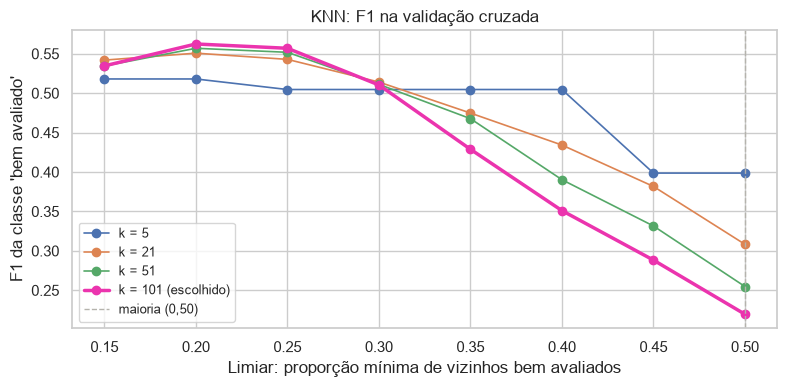

In [96]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
valores_k = [5, 11, 21, 31, 51, 71, 101]
limiares = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

f1_validacao = {}
for k in valores_k:
    proporcao_vizinhos = cross_val_predict(
        criar_knn(k), X_treino, y_treino, cv=validacao, method="predict_proba",
    )[:, 1]
    f1_validacao[k] = [f1_score(y_treino, (proporcao_vizinhos >= limiar).astype(int)) for limiar in limiares]

resultados = pd.DataFrame(f1_validacao, index=limiares).T
resultados.index.name = "k"
resultados.columns.name = "limiar"
melhor_k, melhor_limiar = resultados.stack().idxmax()
melhor_k, melhor_limiar = int(melhor_k), float(melhor_limiar)

print("F1 validação cruzada (linhas = k; colunas = limiar de votação):")
display(resultados.style.format("{:.3f}").highlight_max(axis=None, color="#ffcaf4"))
print(f"k = 5, maioria = 0,50 F1 = {resultados.loc[5, 0.50]:.3f}")
print(f"Escolhido: k = {melhor_k} e limiar = {melhor_limiar:.2f}".replace(".", ",") + f" F1 = {resultados.loc[melhor_k, melhor_limiar]:.3f}")

figura, eixo = plt.subplots()
for k in [5, 21, 51, melhor_k]:
    if k in resultados.index:
        destaque = k == melhor_k
        eixo.plot(limiares, resultados.loc[k], marker="o", linewidth=2.5 if destaque else 1.2,
                  color=COR_DESTAQUE if destaque else None, label=f"k = {k}" + (" (escolhido)" if destaque else ""))
eixo.axvline(0.5, color=COR_NEUTRA, linestyle="--", linewidth=1, label="maioria (0,50)")
eixo.set(title="KNN: F1 na validação cruzada",
         xlabel="Limiar: proporção mínima de vizinhos bem avaliados", ylabel="F1 da classe 'bem avaliado'")
eixo.legend(fontsize=9)
figura.tight_layout()
plt.show()

## Treinamento final e previsões

Com `k` e limiar escolhidos pela validação cruzada, o modelo final é treinado em todo o conjunto de treino (6.781 filmes) e usado para prever os 1.696 filmes do teste, que não participaram da escolha do `k`/limiar nem do treino. Para comparação, também é treinado o KNN "como na aula" (`k = 5`, limiar padrão de 0,50), sem o ajuste por validação cruzada.


In [97]:
limiar_txt = f"{melhor_limiar:.2f}".replace(".", ",")
modelo_knn = criar_knn(melhor_k).fit(X_treino, y_treino)
proporcao_teste = modelo_knn.predict_proba(X_teste)[:, 1]
previsoes_knn = (proporcao_teste >= melhor_limiar).astype(int)

modelo_aula = criar_knn(5).fit(X_treino, y_treino)
previsoes_aula = modelo_aula.predict(X_teste)

colunas_preparadas = modelo_knn.named_steps["preparacao"].get_feature_names_out()
print(f"KNN final: k = {melhor_k}, limiar = {limiar_txt}, {len(colunas_preparadas)} entradas após a preparação")
print(f"Foram previstas {len(previsoes_knn):,} classes no teste e"
      f"{int(previsoes_knn.sum()):,} filmes previstos como bem avaliados")

KNN final: k = 101, limiar = 0,20, 46 entradas após a preparação
Foram previstas 1,696 classes no teste e790 filmes previstos como bem avaliados


## Avaliação no teste

Quatro métricas no conjunto de teste, com a classe positiva = "bem avaliado":
- **acurácia:** proporção de previsões corretas (positivas e negativas);
- **precisão:** dos filmes previstos como bem avaliados, quantos realmente são;
- **recall:** dos filmes realmente bem avaliados, quantos o modelo encontrou;
- **F1:** média harmônica entre precisão e recall, resume as duas em uma métrica só.

**Resultado do KNN ajustado (k = 101, limiar 0,20):** acurácia 66,6%, precisão 46,7%, recall 71,7%, F1 0,566. A matriz de confusão mostra 369 verdadeiros positivos, 146 falsos negativos, 421 falsos positivos e 760 verdadeiros negativos: o modelo encontra a maior parte dos filmes bem avaliados (369 de 515, recall de 71,7%), mas erra ao classificar como "bem avaliado" boa parte dos que não são (421 falsos positivos), por isso a precisão fica abaixo de 50%.


Acuracia: 66.6% Precisão: 46.7% | Recall: 71.7% F1: 0.566


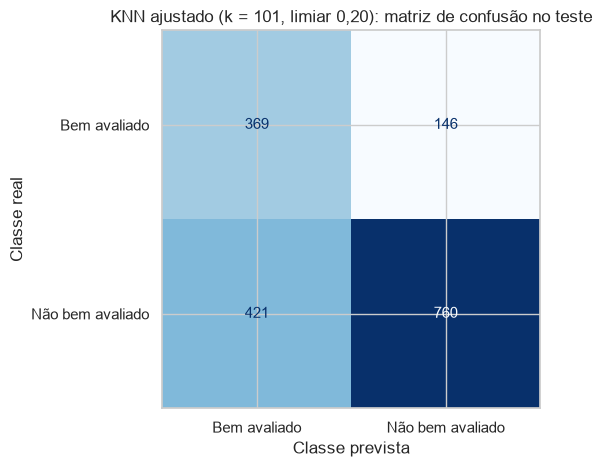

VP: 369 | FN: 146 | FP: 421 | VN: 760
Leitura: dos 515 filmes bem avaliados do teste, o modelo encontrou 369;
421 filmes não bem avaliados foram previstos como bem avaliados


In [98]:
def avaliar(nome, previsoes):
    """Calcula as métricas no teste, com classe positiva = bem avaliado (1)"""
    return {
        "modelo": nome,
        "acurácia": accuracy_score(y_teste, previsoes),
        "precisão": precision_score(y_teste, previsoes, zero_division=0),
        "recall": recall_score(y_teste, previsoes, zero_division=0),
        "F1": f1_score(y_teste, previsoes, zero_division=0),
    }


metricas_knn = avaliar(f"KNN ajustado (k = {melhor_k}, limiar {limiar_txt})", previsoes_knn)
print(f"Acuracia: {metricas_knn['acurácia']:.1%} Precisão: {metricas_knn['precisão']:.1%} | "
      f"Recall: {metricas_knn['recall']:.1%} F1: {metricas_knn['F1']:.3f}")

matriz = confusion_matrix(y_teste, previsoes_knn, labels=[1, 0])
figura, eixo = plt.subplots(figsize=(6.8, 4.8))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Bem avaliado", "Não bem avaliado"],
).plot(ax=eixo, cmap="Blues", colorbar=False, values_format="d")
eixo.set(title=f"KNN ajustado (k = {melhor_k}, limiar {limiar_txt}): matriz de confusão no teste",
         xlabel="Classe prevista", ylabel="Classe real")
figura.tight_layout()
plt.show()

vp, fn = matriz[0]
fp, vn = matriz[1]
print(f"VP: {vp} | FN: {fn} | FP: {fp} | VN: {vn}")
print(f"Leitura: dos {vp + fn} filmes bem avaliados do teste, o modelo encontrou {vp};")
print(f"{fp} filmes não bem avaliados foram previstos como bem avaliados")

## Comparação com os chutes simples

Resultado final no teste, para os quatro modelos (classe positiva = bem avaliado):

| Modelo | Acurácia | F1 |
|---|---|---|
| Chute: classe mais frequente | 0,70 | 0,00 |
| Chute: sorteio proporcional | 0,57 | 0,29 |
| KNN como na aula (k = 5, limiar 0,50) | 0,72 | 0,42 |
| **KNN ajustado (k = 101, limiar 0,20)** | 0,67 | **0,57** |

**Interpretação:** olhar só a acurácia é enganoso aqui — o chute da classe mais frequente tem a segunda maior acurácia (0,70) só porque "não bem avaliado" é a classe maioria, mas nunca acerta um filme bem avaliado (F1 = 0,00). O F1 mostra o que a acurácia esconde: o KNN ajustado tem o maior F1 (0,57), bem acima dos dois chutes (0,00 e 0,29) e também acima do KNN sem ajuste de limiar (0,42). Isso confirma que as features escolhidas (duração, década, mês, idioma, franquia e gêneros) carregam algum sinal real sobre a nota do público — o modelo aprende algo, mesmo que o resultado seja modesto e não sirva para decisões de alta confiança.


,acurácia,precisão,recall,F1
modelo,,,,
Chute: classe mais frequente,69.6%,0.0%,0.0%,0.000
Chute: sorteio proporcional,57.4%,29.6%,29.3%,0.295
"KNN como na aula (k = 5, maioria)",72.3%,57.9%,32.6%,0.417
"KNN ajustado (k = 101, limiar 0,20)",66.6%,46.7%,71.7%,0.566


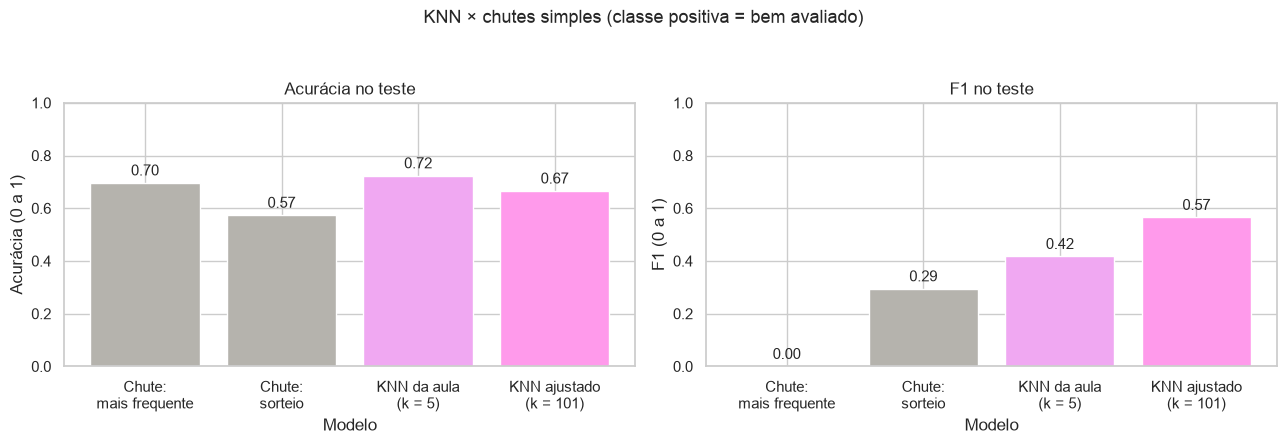

In [99]:
comparacao = pd.DataFrame([
    avaliar("Chute: classe mais frequente", chute_frequente.predict(X_teste)),
    avaliar("Chute: sorteio proporcional", chute_sorteio.predict(X_teste)),
    avaliar("KNN como na aula (k = 5, maioria)", previsoes_aula),
    metricas_knn,
]).set_index("modelo")
display(comparacao.style.format({
    "acurácia": "{:.1%}", "precisão": "{:.1%}", "recall": "{:.1%}", "F1": "{:.3f}",
}))

figura, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
cores = [COR_NEUTRA, COR_NEUTRA, "#f0a8f2", COR_PRINCIPAL]
rotulos = ["Chute:\nmais frequente", "Chute:\nsorteio", "KNN da aula\n(k = 5)", f"KNN ajustado\n(k = {melhor_k})"]
for eixo, metrica, limite in zip(eixos, ["acurácia", "F1"], [1, 1]):
    barras = eixo.bar(rotulos, comparacao[metrica], color=cores)
    eixo.bar_label(barras, labels=[f"{v:.2f}" for v in comparacao[metrica]], padding=3)
    eixo.set_ylim(0, limite)
    eixo.set_title(f"{metrica.capitalize()} no teste")
    eixo.set_ylabel(f"{metrica.capitalize()} (0 a 1)")
    eixo.set_xlabel("Modelo")
figura.suptitle("KNN × chutes simples (classe positiva = bem avaliado)")
figura.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# RA3 — Parte 4: Representatividade e conclusões


## Representatividade da base

- **Origem e abrangência:** a base vem do TMDB, um catálogo colaborativo mantido por usuários, extraído em outubro de 2022. Ela não é uma amostra aleatória do cinema de terror: reflete o que foi cadastrado no TMDB até aquele momento, com viés para filmes em inglês e de produção americana/europeia (a participação de outros idiomas já caiu de 50% nos anos 1960 para menos de 30% a partir dos anos 2000 — ver P1).
- **Retrato de um instante:** `popularity` e `vote_average`/`vote_count` são medidos no momento da coleta. Um filme lançado pouco antes de outubro de 2022 teve menos tempo para acumular votos e popularidade do que um filme antigo, o que pode subestimar lançamentos recentes nessas variáveis.
- **Dados financeiros raros e enviesados:** só cerca de 3% dos filmes (1.010 de 32.404) têm orçamento e receita informados — a análise de retorno (P3, P6 e a estatística descritiva da Parte 1) vale só para esse subconjunto. Como filmes bem-sucedidos têm mais chance de ter a bilheteria registrada, esse subconjunto provavelmente superestima o retorno típico do terror de baixo orçamento.
- **Nota pouco confiável com poucos votos:** por isso o projeto usa `nota_confiavel` (10 votos ou mais) sempre que a nota entra na análise, o que reduz a base de 32.404 para 8.477 filmes nessas partes — outra fonte de viés, já que filmes mais obscuros ficam de fora.
- **Consequência para o modelo de machine learning:** o modelo da Parte 3 herda esses vieses — aprende a prever a nota de filmes com votação suficiente para ter uma nota confiável, majoritariamente em inglês e cadastrados no TMDB até 2022, não do cinema de terror como um todo.


## Conclusões do RA3

- Nota e duração são variáveis estáveis e bem comportadas; orçamento, receita, retorno e popularidade são fortemente concentrados em poucos filmes, por isso a mediana (não a média) é a medida certa para descrevê-las, confirmando a escolha já feita nas respostas do RA1.
- Os gráficos revisados na Parte 2 sustentam os mesmos achados do RA1: orçamento maior está fracamente associado a nota maior; filmes baratos têm retorno proporcional maior (não maior chance de se pagar); outubro concentra lançamentos sem ser mais popular; franquias faturam muito mais que avulsos sem serem muito melhor avaliadas.
- O modelo de machine learning da Parte 3 aprende um padrão real, mas limitado: F1 de 0,57 no teste, bem acima dos chutes simples (0,00 e 0,29) e do KNN sem ajuste de limiar (0,42), prevendo corretamente 72% dos filmes bem avaliados à custa de alguns falsos positivos. Duração, década, idioma, franquia e gênero carregam algum sinal sobre a avaliação do público, mas não o suficiente para uma previsão de alta confiança — o que é esperado, já que fatores que o TMDB não registra (roteiro, elenco, marketing, crítica) pesam na nota.
- **Limitação central do projeto:** quase todas as conclusões sobre dinheiro (orçamento, receita, retorno) valem só para os ~3% de filmes com esses dados informados, e as conclusões sobre nota valem só para os ~26% com votação suficiente. A base descreve bem o catálogo de terror do TMDB até outubro de 2022, majoritariamente em inglês, mas não permite afirmações seguras sobre o universo completo do gênero.
